# Lab Assignment: Landmark Recognition Using SIFT
**Pipeline:** Dataset → SIFT features → Query processing → BFMatcher (L2) + kNN (k=2) + Lowe ratio test → RANSAC homography localization → Evaluation

> **Runtime note:** OpenCV's SIFT and `BFMatcher` run on the **CPU** (the pip build has no CUDA SIFT), so the T4 GPU is not what speeds this up.
> Speed comes from: resizing images to a max side of 800 px, capping keypoints, multi-threaded feature extraction, and caching descriptors to disk.
> Just run **Runtime → Run all**.

## 0. Setup

In [1]:
!pip -q install kagglehub
import os, re, glob, shutil, random, pickle, time, warnings
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

warnings.filterwarnings("ignore")
print("OpenCV:", cv2.__version__)
assert hasattr(cv2, "SIFT_create"), "SIFT not available in this OpenCV build"

OpenCV: 4.14.0


## 1. Configuration (all tunable parameters in one place)

In [2]:
SEED          = 42
MAX_DIM       = 800     # resize longest image side to this (big speedup, little accuracy loss)
N_FEATURES    = 2000    # max SIFT keypoints per image
N_REF         = 8       # reference images per landmark (database)
N_QUERY       = 4       # held-out query images per landmark (never in the database)
N_LANDMARKS   = 6       # number of landmarks in the database (>= 5 required)

RATIO         = 0.75    # Lowe's ratio threshold
RANSAC_THRESH = 5.0     # reprojection threshold (pixels)
MIN_GOOD      = 20      # min reliable matches (after ratio test) to accept
MIN_INLIERS   = 12      # min RANSAC inliers to accept
MIN_MARGIN    = 1.3     # best landmark inliers must be >= MIN_MARGIN x runner-up inliers
MIN_HOMOG_PTS = 8       # min matches needed to even attempt a homography

# Keywords used to pick landmark classes from the Kaggle folders (case/space-insensitive)
LANDMARK_KEYWORDS = {
    "Taj Mahal":           ["tajmahal", "taj"],
    "Great Wall of China": ["greatwall"],
    "Statue of Liberty":   ["liberty"],
    "Colosseum":           ["colosseum", "coliseum"],
    "Pyramids of Giza":    ["pyramid", "giza"],
    "Christ the Redeemer": ["redeemer", "christ"],
    "Eiffel Tower":        ["eiffel"],
    "Machu Picchu":        ["machu"],
    "Chichen Itza":        ["chichen"],
}
# Classes to hold out and use ONLY as "unknown landmark" queries (not in database)
UNKNOWN_KEYWORDS = ["petra", "stonehenge", "angel", "machu", "chichen"]

random.seed(SEED); np.random.seed(SEED)
DB_DIR, QUERY_DIR, OUT_DIR = "/content/landmark_db", "/content/query_pool", "/content/outputs"
for d in (DB_DIR, QUERY_DIR, OUT_DIR): os.makedirs(d, exist_ok=True)

## 2. Download dataset & discover its structure

In [3]:
path = kagglehub.dataset_download("balabaskar/wonders-of-the-world-image-classification")
print("Path to dataset files:", path)

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
norm = lambda s: re.sub(r"[^a-z0-9]", "", s.lower())

# class name = name of the folder that directly contains the images (train/valid/test splits are merged)
classes = defaultdict(list)
for dp, _, files in os.walk(path):
    imgs = [os.path.join(dp, f) for f in files if f.lower().endswith(IMG_EXT)]
    if imgs:
        classes[os.path.basename(dp)].extend(imgs)

print(f"\nFound {len(classes)} classes:")
for k, v in sorted(classes.items()):
    print(f"  {k:35s} {len(v):5d} images")

100%|██████████| 432M/432M [00:21<00:00, 20.7MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/balabaskar/wonders-of-the-world-image-classification/versions/2

Found 12 classes:
  burj_khalifa                          390 images
  chichen_itza                          340 images
  christ_the_reedemer                   323 images
  eiffel_tower                          391 images
  great_wall_of_china                   392 images
  machu_pichu                           393 images
  pyramids_of_giza                      372 images
  roman_colosseum                       394 images
  statue_of_liberty                     238 images
  stonehenge                            204 images
  taj_mahal                             158 images
  venezuela_angel_falls                 251 images


## 3. Task 1 — Landmark image database

Database landmarks: ['Taj Mahal', 'Great Wall of China', 'Statue of Liberty', 'Colosseum', 'Pyramids of Giza', 'Christ the Redeemer']
Unknown (not in DB): stonehenge

Database folder structure:
  Christ the Redeemer       8 reference images
  Colosseum                 8 reference images
  Great Wall of China       8 reference images
  Pyramids of Giza          8 reference images
  Statue of Liberty         8 reference images
  Taj Mahal                 8 reference images


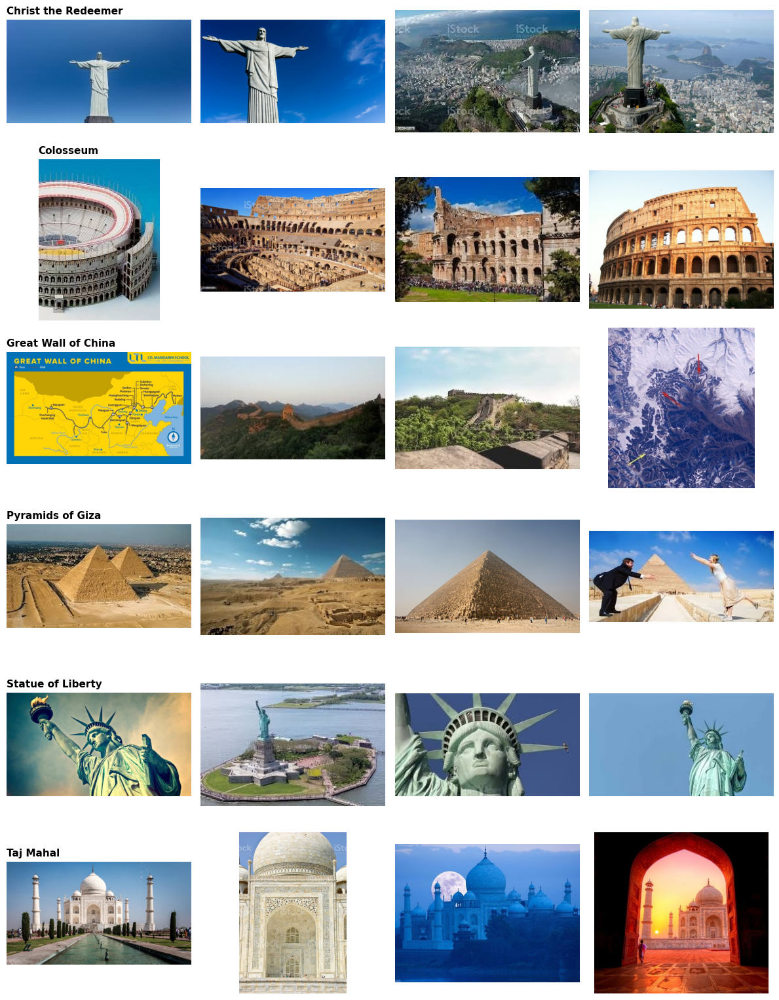

In [4]:
def find_class(keywords, exclude=()):
    for cname in classes:
        if cname in exclude: continue
        n = norm(cname)
        if any(k in n for k in keywords):
            return cname
    return None

# --- choose database landmarks
db_classes = {}                      # pretty name -> folder class name
for pretty, kws in LANDMARK_KEYWORDS.items():
    c = find_class(kws)
    if c and len(classes[c]) >= N_REF + N_QUERY and c not in db_classes.values():
        db_classes[pretty] = c
    if len(db_classes) == N_LANDMARKS: break

# --- choose the unknown (held-out) class
unk_class = None
for kw in UNKNOWN_KEYWORDS:
    c = find_class([kw], exclude=db_classes.values())
    if c: unk_class = c; break
if unk_class is None:
    unk_class = next(c for c in classes if c not in db_classes.values())

# --- fallback: if fewer than 5 keyword matches, fill with the largest remaining classes
if len(db_classes) < 5:
    for c in sorted(classes, key=lambda k: -len(classes[k])):
        if c not in db_classes.values() and c != unk_class and len(classes[c]) >= N_REF + N_QUERY:
            db_classes[c] = c
        if len(db_classes) >= 5: break

print("Database landmarks:", list(db_classes.keys()))
print("Unknown (not in DB):", unk_class)

# --- build folders: DB/<Landmark>/ref_XX.jpg  and  query_pool/<Landmark>/q_XX.jpg
def load_resized(p, max_dim=MAX_DIM):
    im = cv2.imread(p)
    if im is None: return None
    h, w = im.shape[:2]
    s = max_dim / max(h, w)
    return cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else im

def copy_set(files, folder, prefix, n):
    os.makedirs(folder, exist_ok=True); out = []
    for p in files:
        if len(out) == n: break
        im = load_resized(p)
        if im is None: continue
        fp = os.path.join(folder, f"{prefix}_{len(out):02d}.jpg"); cv2.imwrite(fp, im); out.append(fp)
    return out

shutil.rmtree(DB_DIR, ignore_errors=True); shutil.rmtree(QUERY_DIR, ignore_errors=True)
query_pool = {}
for pretty, c in db_classes.items():
    files = classes[c][:]; random.shuffle(files)
    copy_set(files[:N_REF*2], os.path.join(DB_DIR, pretty), "ref", N_REF)          # reference images
    query_pool[pretty] = copy_set(files[N_REF*2:], os.path.join(QUERY_DIR, pretty), "q", N_QUERY)   # held-out
    if len(query_pool[pretty]) < N_QUERY:   # dataset small: take queries from leftover of first slice
        query_pool[pretty] += copy_set(files[N_REF:N_REF*2], os.path.join(QUERY_DIR, pretty), "qx", N_QUERY-len(query_pool[pretty]))
ufiles = classes[unk_class][:]; random.shuffle(ufiles)
unknown_queries = copy_set(ufiles, os.path.join(QUERY_DIR, "_unknown_"+unk_class), "u", N_QUERY)

print("\nDatabase folder structure:")
for d in sorted(os.listdir(DB_DIR)):
    print(f"  {d:25s} {len(os.listdir(os.path.join(DB_DIR, d)))} reference images")

# --- preview grid
names = sorted(os.listdir(DB_DIR))
fig, axs = plt.subplots(len(names), 4, figsize=(12, 2.6*len(names)))
for i, n in enumerate(names):
    for j, f in enumerate(sorted(os.listdir(os.path.join(DB_DIR, n)))[:4]):
        axs[i, j].imshow(cv2.cvtColor(cv2.imread(os.path.join(DB_DIR, n, f)), cv2.COLOR_BGR2RGB)); axs[i, j].axis("off")
    axs[i, 0].set_title(n, loc="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/task1_database_preview.png", dpi=120); plt.show()

## 4. Task 2 — SIFT feature extraction on reference images

Extracted SIFT from 48 reference images in 6.2s  (saved -> /content/sift_db.pkl)
                     images  avg_keypoints
Landmark                                  
Christ the Redeemer       8          938.0
Colosseum                 8         1132.0
Great Wall of China       8          586.0
Pyramids of Giza          8          533.0
Statue of Liberty         8          434.0
Taj Mahal                 8         1081.0


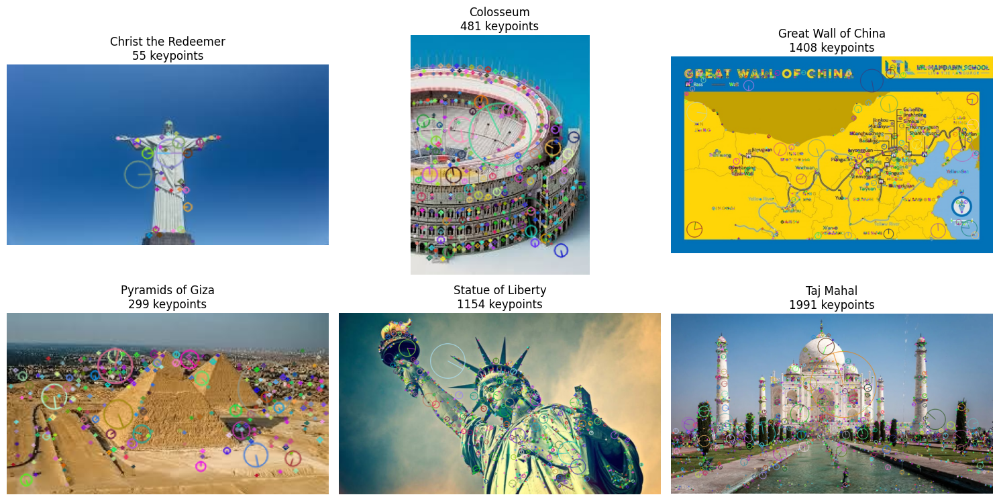

In [5]:
def make_sift(): return cv2.SIFT_create(nfeatures=N_FEATURES)

def extract(img_bgr):
    """grayscale -> SIFT keypoints + 128-d descriptors"""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    kp, des = make_sift().detectAndCompute(gray, None)
    return gray, kp, des

kp_to_t = lambda k: (k.pt, k.size, k.angle, k.response, k.octave, k.class_id)
t_to_kp = lambda t: cv2.KeyPoint(x=t[0][0], y=t[0][1], size=t[1], angle=t[2], response=t[3], octave=t[4], class_id=t[5])

def process_ref(args):
    label, fp = args
    img = cv2.imread(fp); _, kp, des = extract(img)
    return dict(label=label, file=fp, shape=img.shape[:2], kp=[kp_to_t(k) for k in kp], des=des)

CACHE = "/content/sift_db.pkl"
t0 = time.time()
jobs = [(n, os.path.join(DB_DIR, n, f)) for n in sorted(os.listdir(DB_DIR)) for f in sorted(os.listdir(os.path.join(DB_DIR, n)))]
with ThreadPoolExecutor(max_workers=os.cpu_count() or 2) as ex:
    db_raw = list(ex.map(process_ref, jobs))
with open(CACHE, "wb") as f: pickle.dump(db_raw, f)          # store descriptors + labels
print(f"Extracted SIFT from {len(db_raw)} reference images in {time.time()-t0:.1f}s  (saved -> {CACHE})")

# rebuild in-memory DB (keypoints as cv2.KeyPoint objects)
db = [dict(label=r["label"], file=r["file"], shape=r["shape"], kp=[t_to_kp(t) for t in r["kp"]], des=r["des"]) for r in db_raw]
print(pd.DataFrame([(d["label"], len(d["kp"])) for d in db], columns=["Landmark", "Keypoints"]).groupby("Landmark").agg(images=("Keypoints","count"), avg_keypoints=("Keypoints","mean")).round(0))

# display one reference image per landmark with keypoints
labels = sorted(set(d["label"] for d in db))
fig, axs = plt.subplots(2, (len(labels)+1)//2, figsize=(5*((len(labels)+1)//2), 8)); axs = axs.ravel()
for ax, lb in zip(axs, labels):
    d = next(x for x in db if x["label"] == lb); img = cv2.imread(d["file"])
    vis = cv2.drawKeypoints(img, d["kp"], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax.set_title(f"{lb}\n{len(d['kp'])} keypoints"); ax.axis("off")
for ax in axs[len(labels):]: ax.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/task2_reference_keypoints.png", dpi=120); plt.show()

## 5. Tasks 3–5 — Query processing, matching, recognition & localization

**Decision logic (so a query is *not* classified just by the largest match count):**
1. Each reference image is matched with `BFMatcher(NORM_L2)` + `knnMatch(k=2)` + Lowe's ratio test → *reliable matches*.
2. A RANSAC homography is estimated for every reference image → *inliers*.
3. Each landmark is scored by its best reference image; landmarks are ranked by (inliers, reliable matches).
4. Recognized only if **all** hold: reliable matches ≥ `MIN_GOOD`, inliers ≥ `MIN_INLIERS`, valid projected polygon (convex, sane area), and best landmark's inliers ≥ `MIN_MARGIN` × runner-up's.
   Otherwise the image is **rejected** as unknown.

------------------------------------------------------------
Demo query (true: Christ the Redeemer)
Ranking (landmark | reliable matches | RANSAC inliers):
   Colosseum                  6     0
   Taj Mahal                  6     0
   Great Wall of China        5     0
   Pyramids of Giza           5     0
   Statue of Liberty          5     0
   Christ the Redeemer        4     0
Decision: REJECTED (too few reliable matches) | matches=6 inliers=0 keypoints=135 time=0.236s


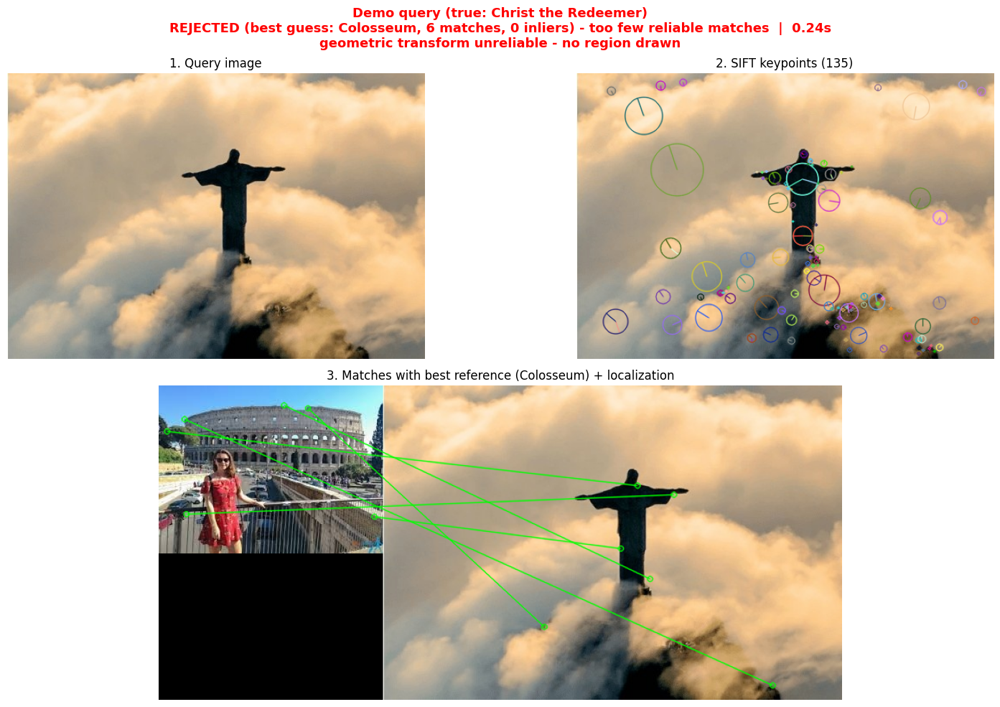

------------------------------------------------------------
Demo query (true: stonehenge, NOT in database)
Ranking (landmark | reliable matches | RANSAC inliers):
   Colosseum                  9     6
   Christ the Redeemer       10     5
   Great Wall of China        9     5
   Pyramids of Giza           8     5
   Statue of Liberty          6     0
   Taj Mahal                  6     0
Decision: REJECTED (too few reliable matches) | matches=9 inliers=6 keypoints=243 time=0.371s


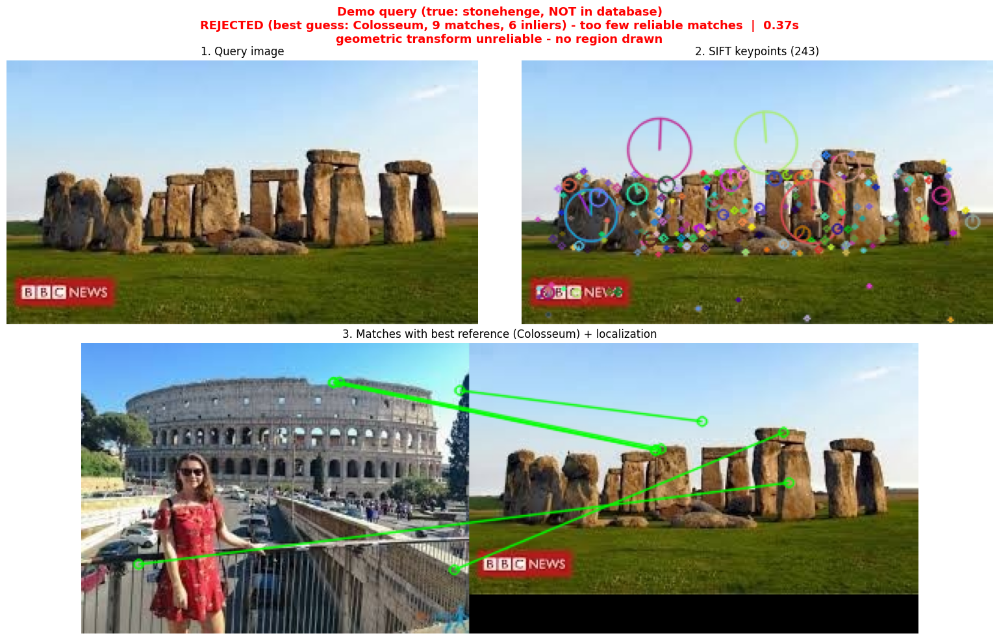

In [6]:
bf = cv2.BFMatcher(cv2.NORM_L2)          # Brute-force, Euclidean distance

def ratio_match(des_q, des_r):
    if des_q is None or des_r is None or len(des_q) < 2 or len(des_r) < 2: return []
    out = []
    for pair in bf.knnMatch(des_q, des_r, k=2):          # k = 2
        if len(pair) == 2 and pair[0].distance < RATIO * pair[1].distance:   # Lowe's ratio test
            out.append(pair[0])
    return out

def polygon_valid(poly, q_shape):
    if poly is None or not np.isfinite(poly).all(): return False
    if not cv2.isContourConvex(poly.reshape(-1, 1, 2).astype(np.float32)): return False
    area = cv2.contourArea(poly.astype(np.float32)); q_area = q_shape[0] * q_shape[1]
    return 0.01 * q_area < area < 3.0 * q_area

def localize(kp_q, kp_r, good, ref_shape, q_shape):
    """RANSAC homography ref->query. Returns (poly, inlier_mask, n_inliers, ok)"""
    if len(good) < MIN_HOMOG_PTS: return None, None, 0, False
    src = np.float32([kp_r[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)   # reference pts
    dst = np.float32([kp_q[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)   # query pts
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_THRESH)
    if H is None: return None, None, 0, False
    inl = int(mask.sum()); h, w = ref_shape
    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    poly = cv2.perspectiveTransform(corners, H).reshape(-1, 2)
    return poly, mask.ravel().astype(bool), inl, polygon_valid(poly, q_shape)

def recognize(img_bgr, show=True, title="", save_as=None, verbose=True):
    t0 = time.perf_counter()
    gray, kp_q, des_q = extract(img_bgr)                                       # Task 3
    res = []
    for d in db:                                                               # Task 4
        good = ratio_match(des_q, d["des"])
        poly, mask, inl, ok = localize(kp_q, d["kp"], good, d["shape"], img_bgr.shape[:2])   # Task 5
        res.append(dict(label=d["label"], entry=d, good=good, poly=poly, mask=mask, inl=inl, ok=ok))

    # aggregate per landmark: best reference image
    best = {}
    for r in res:
        key = (r["inl"], len(r["good"]))
        if r["label"] not in best or key > (best[r["label"]]["inl"], len(best[r["label"]]["good"])): best[r["label"]] = r
    ranking = sorted(best.values(), key=lambda r: (r["inl"], len(r["good"])), reverse=True)
    top = ranking[0]; second_inl = ranking[1]["inl"] if len(ranking) > 1 else 0

    n_good, n_inl = len(top["good"]), top["inl"]
    margin_ok = n_inl >= MIN_MARGIN * max(second_inl, 1)
    recognized = n_good >= MIN_GOOD and n_inl >= MIN_INLIERS and top["ok"] and margin_ok
    reason = ("OK" if recognized else
              "too few reliable matches" if n_good < MIN_GOOD else
              "too few RANSAC inliers" if n_inl < MIN_INLIERS else
              "unreliable geometry (invalid polygon)" if not top["ok"] else
              "ambiguous (runner-up too close)")
    elapsed = time.perf_counter() - t0

    out = dict(predicted=top["label"] if recognized else "Unknown (rejected)", best_guess=top["label"],
               n_keypoints=len(kp_q), n_good=n_good, n_inliers=n_inl, recognized=recognized,
               reason=reason, time_s=elapsed, ranking=[(r["label"], len(r["good"]), r["inl"]) for r in ranking])

    if verbose:
        print(f"{'-'*60}\n{title}\nRanking (landmark | reliable matches | RANSAC inliers):")
        for lb, g, i in out["ranking"]: print(f"   {lb:22s} {g:5d} {i:5d}")
        print(f"Decision: {'RECOGNIZED -> ' + top['label'] if recognized else 'REJECTED (' + reason + ')'} | "
              f"matches={n_good} inliers={n_inl} keypoints={len(kp_q)} time={elapsed:.3f}s")

    if show or save_as:
        ref_img = cv2.imread(top["entry"]["file"])
        q_kp_vis = cv2.drawKeypoints(img_bgr, kp_q, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
        q_loc = img_bgr.copy(); msg = ""
        if recognized:
            cv2.polylines(q_loc, [top["poly"].astype(np.int32).reshape(-1, 1, 2)], True, (0, 0, 255), 4)
        else:
            msg = "geometric transform unreliable - no region drawn"
        inl_matches = [m for m, k in zip(top["good"], top["mask"]) if k] if top["mask"] is not None else top["good"]
        inl_matches = sorted(inl_matches, key=lambda m: m.distance)[:80]
        # drawMatches expects (img1=ref, img2=query): swap indices of query->ref matches
        dm = [cv2.DMatch(m.trainIdx, m.queryIdx, m.distance) for m in inl_matches]
        match_vis = cv2.drawMatches(ref_img, top["entry"]["kp"], q_loc, kp_q, dm, None,
                                    matchColor=(0, 255, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
        fig = plt.figure(figsize=(16, 10)); gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.1])
        a1, a2, a3 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])
        a1.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)); a1.set_title("1. Query image")
        a2.imshow(cv2.cvtColor(q_kp_vis, cv2.COLOR_BGR2RGB)); a2.set_title(f"2. SIFT keypoints ({len(kp_q)})")
        a3.imshow(cv2.cvtColor(match_vis, cv2.COLOR_BGR2RGB))
        a3.set_title(f"3. Matches with best reference ({top['label']}) + localization", fontsize=12)
        for a in (a1, a2, a3): a.axis("off")
        status = (f"RECOGNIZED: {top['label']}  |  reliable matches: {n_good}  |  RANSAC inliers: {n_inl}" if recognized
                  else f"REJECTED (best guess: {top['label']}, {n_good} matches, {n_inl} inliers) - {reason}")
        fig.suptitle(f"{title}\n{status}  |  {elapsed:.2f}s" + (f"\n{msg}" if msg else ""), fontsize=13,
                     color="green" if recognized else "red", fontweight="bold")
        plt.tight_layout()
        if save_as: plt.savefig(os.path.join(OUT_DIR, save_as), dpi=120, bbox_inches="tight")
        if show: plt.show()
        plt.close(fig)
    return out

# --- demo: one known query + one unknown query
first = sorted(query_pool)[0]
_ = recognize(cv2.imread(query_pool[first][0]), title=f"Demo query (true: {first})", save_as="demo_known.png")
_ = recognize(cv2.imread(unknown_queries[0]), title=f"Demo query (true: {unk_class}, NOT in database)", save_as="demo_unknown.png")

## 6. Task 6 — Performance evaluation under different conditions

In [7]:
def rotate_bound(img, angle=45):
    h, w = img.shape[:2]; c = (w/2, h/2); M = cv2.getRotationMatrix2D(c, angle, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1]); nw, nh = int(h*sin + w*cos), int(h*cos + w*sin)
    M[0, 2] += nw/2 - c[0]; M[1, 2] += nh/2 - c[1]
    return cv2.warpAffine(img, M, (nw, nh))                      # black borders, nothing cropped

variants = {
    "Original":           lambda p, p2: cv2.imread(p),
    "Rotated (45 deg)":   lambda p, p2: rotate_bound(cv2.imread(p), 45),
    "Resized (50%)":      lambda p, p2: cv2.resize(cv2.imread(p), None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA),
    "Low brightness":     lambda p, p2: cv2.convertScaleAbs(cv2.imread(p), alpha=0.35, beta=0),
    "Different viewpoint":lambda p, p2: cv2.imread(p2),
}

rows = []
for lb in sorted(query_pool):
    qs = query_pool[lb]; p, p2 = qs[0], qs[1]
    for cond, fn in variants.items():
        r = recognize(fn(p, p2), show=False, verbose=False)
        correct = r["recognized"] and r["predicted"] == lb
        rows.append(dict(True_Landmark=lb, Condition=cond, Predicted=r["predicted"], Keypoints=r["n_keypoints"],
                         Reliable_Matches=r["n_good"], RANSAC_Inliers=r["n_inliers"],
                         Decision="Recognized" if r["recognized"] else "Rejected",
                         Correct=correct, Time_s=round(r["time_s"], 3)))
for i, up in enumerate(unknown_queries[:2]):
    r = recognize(cv2.imread(up), show=False, verbose=False)
    rows.append(dict(True_Landmark=f"{unk_class} (not in DB)", Condition=f"Unknown landmark #{i+1}", Predicted=r["predicted"],
                     Keypoints=r["n_keypoints"], Reliable_Matches=r["n_good"], RANSAC_Inliers=r["n_inliers"],
                     Decision="Recognized" if r["recognized"] else "Rejected", Correct=not r["recognized"], Time_s=round(r["time_s"], 3)))

results = pd.DataFrame(rows)
results.to_csv(f"{OUT_DIR}/experimental_results.csv", index=False)
pd.set_option("display.width", 220, "display.max_rows", 200)
display(results)

print("\n=== Summary ===")
print(f"Overall accuracy: {results.Correct.mean()*100:.1f}%  ({results.Correct.sum()}/{len(results)})")
print(results.groupby("Condition").agg(accuracy=("Correct", "mean"), avg_matches=("Reliable_Matches", "mean"),
                                       avg_inliers=("RANSAC_Inliers", "mean"), avg_time_s=("Time_s", "mean")).round(2))

,True_Landmark,Condition,Predicted,Keypoints,Reliable_Matches,RANSAC_Inliers,Decision,Correct,Time_s
0,Christ the Redeemer,Original,Unknown (rejected),135,6,0,Rejected,False,0.259
1,Christ the Redeemer,Rotated (45 deg),Unknown (rejected),168,11,5,Rejected,False,0.330
2,Christ the Redeemer,Resized (50%),Unknown (rejected),107,6,0,Rejected,False,0.122
3,Christ the Redeemer,Low brightness,Unknown (rejected),41,3,0,Rejected,False,0.080
4,Christ the Redeemer,Different viewpoint,Unknown (rejected),319,15,13,Rejected,False,0.378
5,Colosseum,Original,Unknown (rejected),541,14,5,Rejected,False,0.866
6,Colosseum,Rotated (45 deg),Unknown (rejected),754,12,7,Rejected,False,1.211
7,Colosseum,Resized (50%),Unknown (rejected),140,8,0,Rejected,False,0.184
8,Colosseum,Low brightness,Unknown (rejected),198,7,0,Rejected,False,0.226
9,Colosseum,Different viewpoint,Unknown (rejected),599,10,5,Rejected,False,0.675



=== Summary ===
Overall accuracy: 9.4%  (3/32)
                     accuracy  avg_matches  avg_inliers  avg_time_s
Condition                                                          
Different viewpoint      0.00        15.50         8.67        0.93
Low brightness           0.00         4.67         0.00        0.11
Original                 0.00        10.50         5.17        0.36
Resized (50%)            0.00         5.00         0.00        0.12
Rotated (45 deg)         0.17        13.83         7.83        0.58
Unknown landmark #1      1.00         9.00         6.00        0.31
Unknown landmark #2      1.00        53.00         7.00        3.33


### Screenshots for the report (one run per condition on the first landmark)

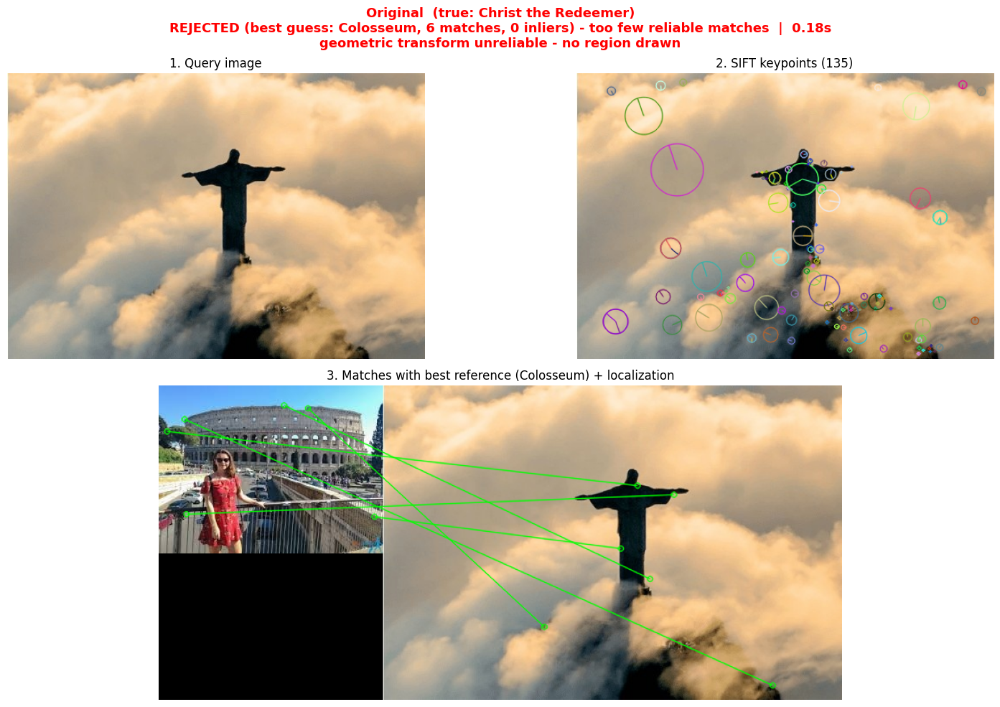

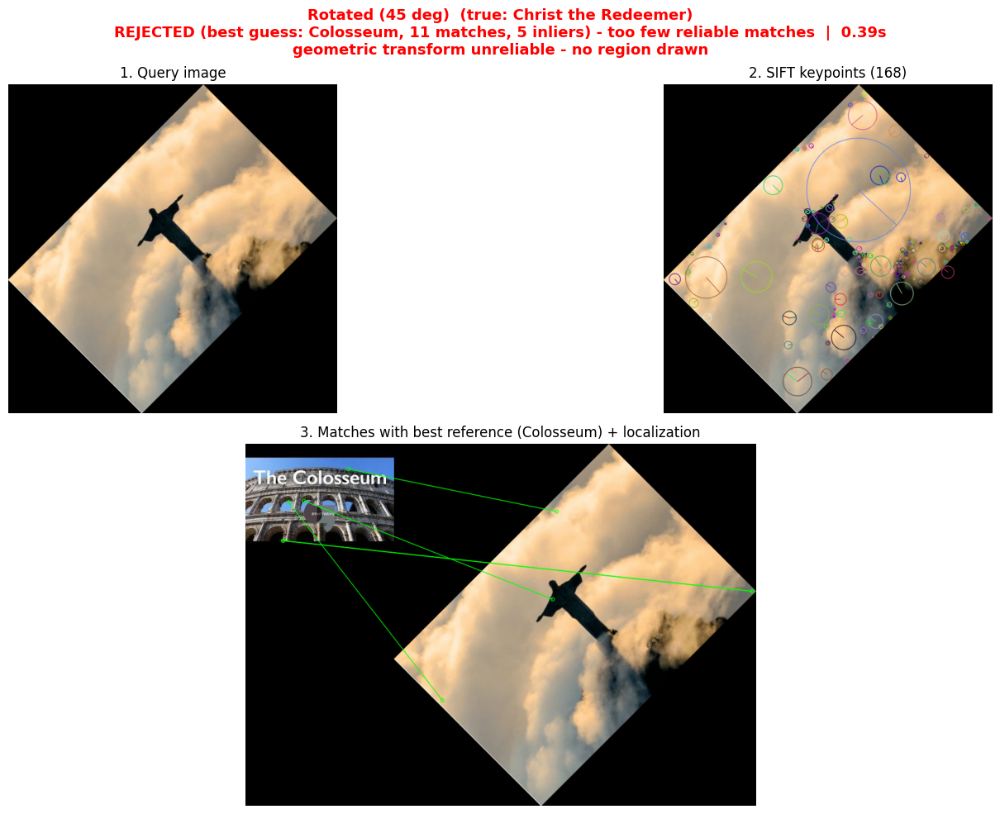

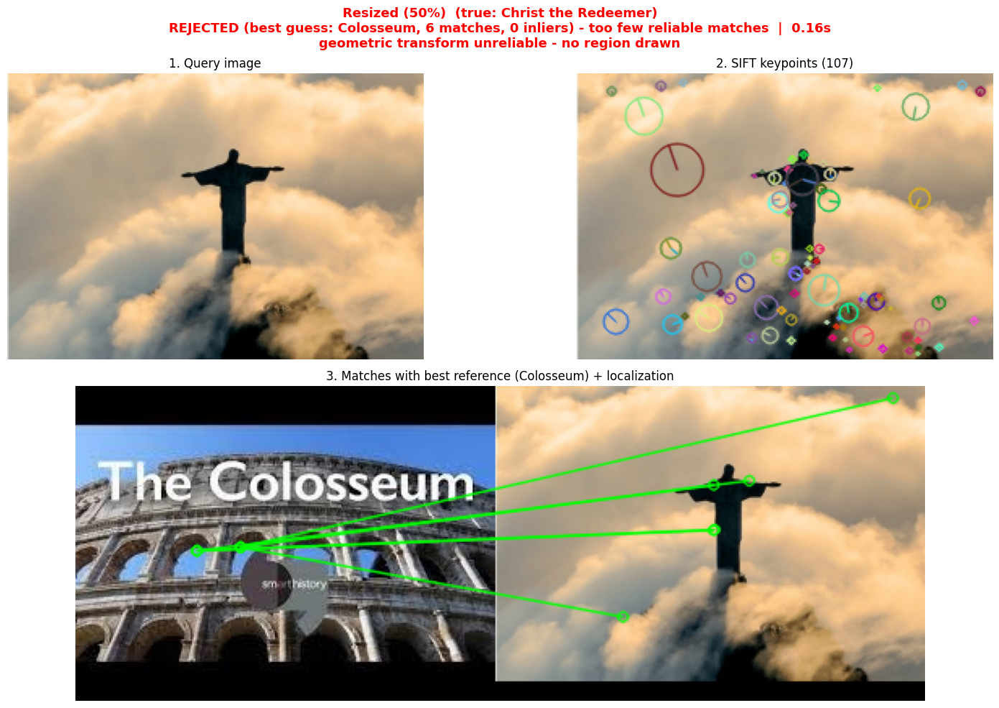

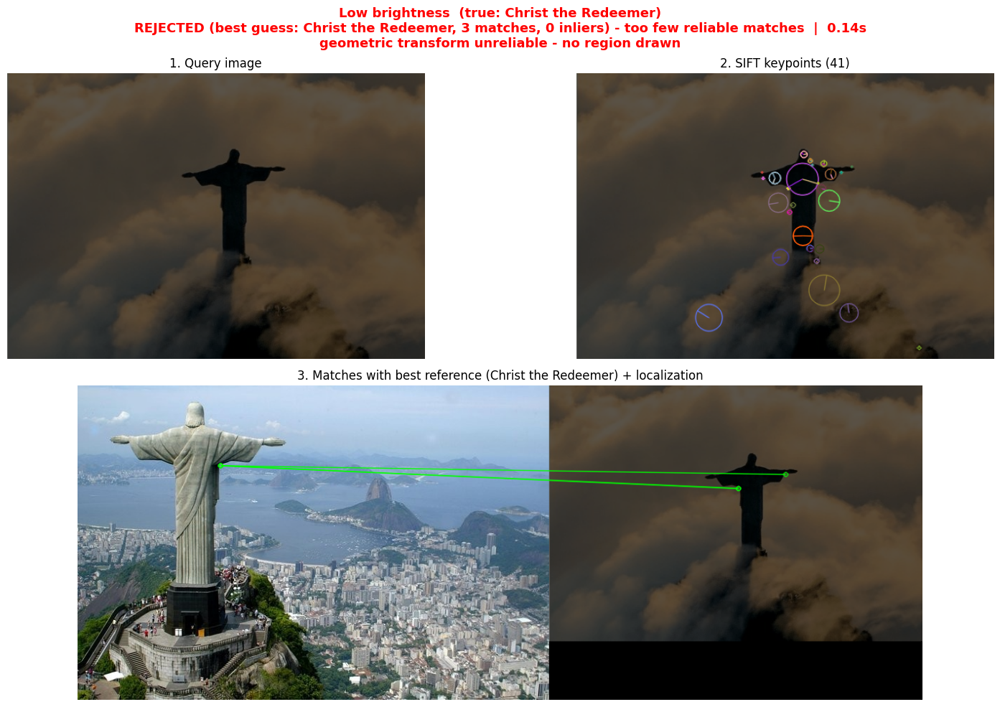

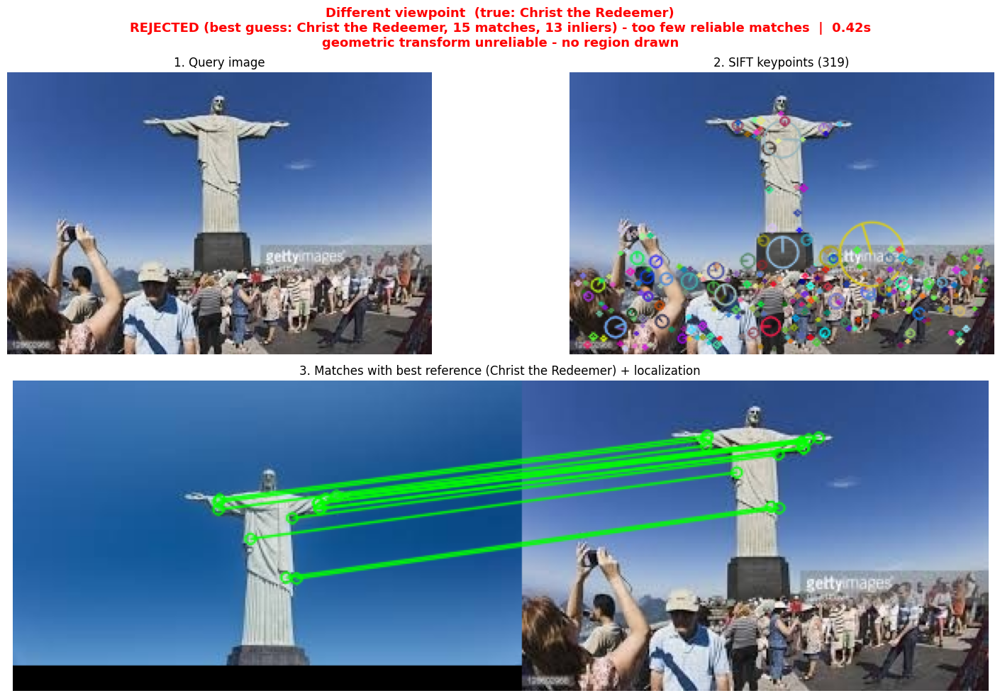

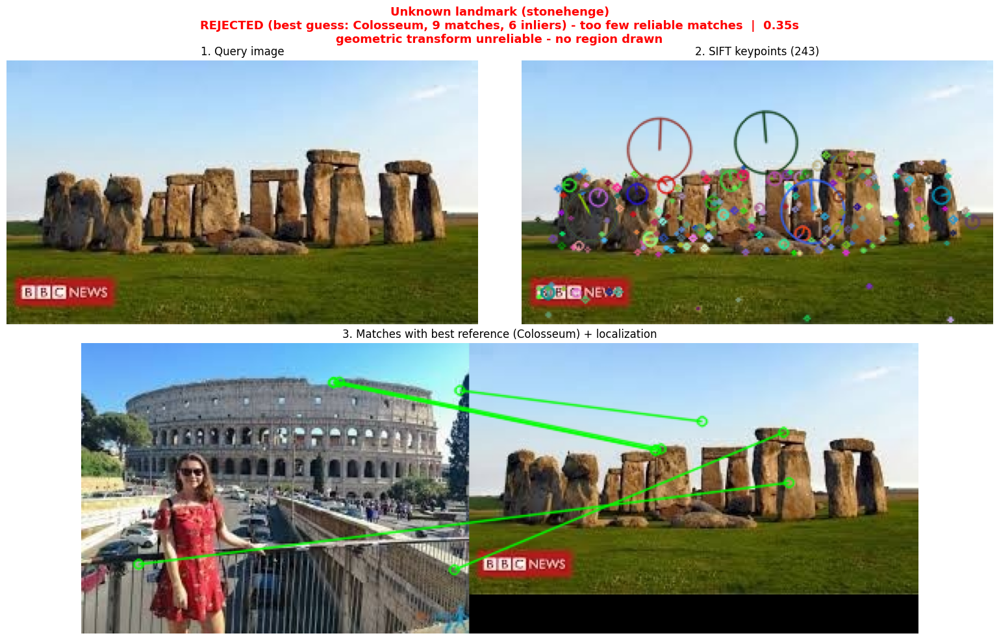

Screenshots saved in /content/outputs


In [8]:
lb = sorted(query_pool)[0]; p, p2 = query_pool[lb][0], query_pool[lb][1]
for cond, fn in variants.items():
    recognize(fn(p, p2), title=f"{cond}  (true: {lb})", save_as=f"shot_{re.sub(r'[^a-z0-9]+','_',cond.lower())}.png", verbose=False)
recognize(cv2.imread(unknown_queries[0]), title=f"Unknown landmark ({unk_class})", save_as="shot_unknown.png", verbose=False)
print("Screenshots saved in", OUT_DIR)

### (Optional) Try your own image — upload any landmark photo

Saving images.jpg to images.jpg
------------------------------------------------------------
Uploaded: images.jpg
Ranking (landmark | reliable matches | RANSAC inliers):
   Christ the Redeemer       57     8
   Statue of Liberty         38     7
   Colosseum                 24     7
   Pyramids of Giza          34     6
   Great Wall of China       25     6
   Taj Mahal                 21     6
Decision: REJECTED (too few RANSAC inliers) | matches=57 inliers=8 keypoints=1407 time=2.352s


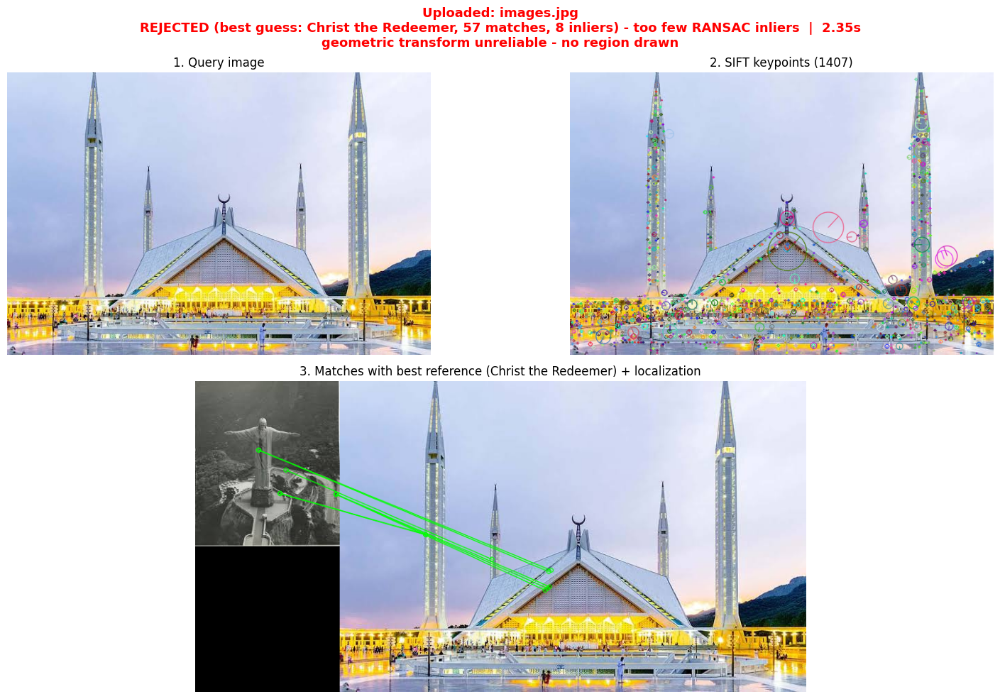

In [9]:
try:
    from google.colab import files
    up = files.upload()
    for name in up:
        im = cv2.imdecode(np.frombuffer(up[name], np.uint8), cv2.IMREAD_COLOR)
        s = MAX_DIM / max(im.shape[:2]); im = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else im
        recognize(im, title=f"Uploaded: {name}")
except Exception as e:
    print("Skipped upload:", e)

### Zip everything for submission

In [10]:
shutil.make_archive("/content/submission_files", "zip", "/content", "outputs")
shutil.make_archive("/content/landmark_database", "zip", DB_DIR)
try:
    from google.colab import files
    files.download("/content/submission_files.zip"); files.download("/content/landmark_database.zip")
except Exception: pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Discussion (edit with your own numbers from the table above)

**Performance.** SIFT keypoints are invariant to scale and rotation and partially robust to illumination, so the *Original*, *Resized*, *Rotated* and *Low-brightness* queries should be recognized with many reliable matches and RANSAC inliers. Using RANSAC inliers (not raw match count) together with a minimum-match threshold and a runner-up margin keeps unknown landmarks from being accepted.

**Limitations.**
- *Viewpoint changes* beyond ~30–40° reduce repeatable keypoints and inlier counts; a single homography also assumes a roughly planar view, which 3D structures violate.
- Landmarks with repetitive texture (Colosseum arches, Great Wall bricks, pyramid blocks) produce ambiguous descriptors.
- Very dark / low-contrast images yield fewer keypoints.
- Reference images are whole photos, so the projected polygon covers the reference frame, not a tight box on the monument.
- Brute-force matching against every reference image scales linearly with database size; FLANN/KD-tree or a bag-of-visual-words index would be needed for a large database.
- Thresholds (`MIN_GOOD`, `MIN_INLIERS`, `MIN_MARGIN`) are tuned empirically and should be re-tuned for a different dataset.